In [1]:
import numpy as np

raw_data = np.genfromtxt("./data/x09.txt", skip_header=36)
raw_data

array([[  1.,   1.,  84.,  46., 354.],
       [  2.,   1.,  73.,  20., 190.],
       [  3.,   1.,  65.,  52., 405.],
       [  4.,   1.,  70.,  30., 263.],
       [  5.,   1.,  76.,  57., 451.],
       [  6.,   1.,  69.,  25., 302.],
       [  7.,   1.,  63.,  28., 288.],
       [  8.,   1.,  72.,  36., 385.],
       [  9.,   1.,  79.,  57., 402.],
       [ 10.,   1.,  75.,  44., 365.],
       [ 11.,   1.,  27.,  24., 209.],
       [ 12.,   1.,  89.,  31., 290.],
       [ 13.,   1.,  65.,  52., 346.],
       [ 14.,   1.,  57.,  23., 254.],
       [ 15.,   1.,  59.,  60., 395.],
       [ 16.,   1.,  69.,  48., 434.],
       [ 17.,   1.,  60.,  34., 220.],
       [ 18.,   1.,  79.,  51., 374.],
       [ 19.,   1.,  75.,  50., 308.],
       [ 20.,   1.,  82.,  34., 220.],
       [ 21.,   1.,  59.,  46., 311.],
       [ 22.,   1.,  67.,  23., 181.],
       [ 23.,   1.,  85.,  37., 274.],
       [ 24.,   1.,  55.,  40., 303.],
       [ 25.,   1.,  63.,  30., 244.]])

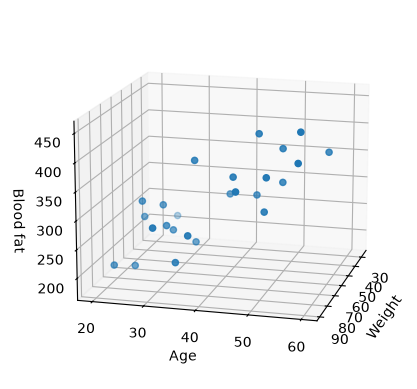

In [ ]:
import matplotlib.pyplot as plt

xs = np.array(raw_data[:, 2], dtype=np.float32) # weight
ys = np.array(raw_data[:, 3], dtype=np.float32) # age
zs = np.array(raw_data[:, 4], dtype=np.float32) # blood fat

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(xs, ys, zs)
ax.set_xlabel('Weight')
ax.set_ylabel('Age')
ax.set_zlabel('Blood fat')
ax.view_init(15, 15)
plt.show()

In [ ]:
x_data = np.array(raw_data[:, 2:4], dtype=np.float32) # weight, age
y_data = np.array(raw_data[:, 4], dtype=np.float32) # blood fat

y_data = y_data.reshape((25, 1))

In [ ]:
import tensorflow as tf

model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(1, input_shape=(2,)),
])

model.compile(optimizer='rmsprop', loss='mse') # mean squard error를 줄이는 방향으로 학습해라

I0000 00:00:1790642743.030141   12186 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790642743.030475   12186 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790642743.074404   12186 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790642743.926997   12186 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
hist = model.fit(x_data, y_data, epochs=10000)

Epoch 1/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - loss: 165680.2969
Epoch 2/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 165398.9531
Epoch 3/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 165195.0938
Epoch 4/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 165024.5312
Epoch 5/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 164873.2344
Epoch 6/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 164734.6562
Epoch 7/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 164605.1875
Epoch 8/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 164482.5469
Epoch 9/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 164365.2031
Epoch 10/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 164252.1406
Epoch 11/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 164142.5312
Epoch 12/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 164035.7812
Epoch 13/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 163931.4375
Epoch 14/10000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss

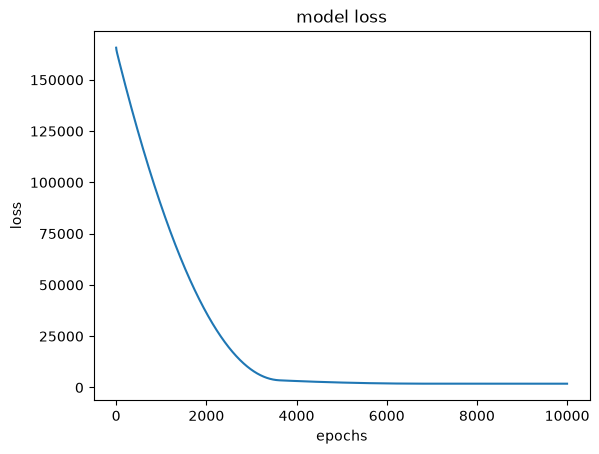

In [7]:
plt.plot(hist.history['loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.show()

In [ ]:
model.predict(np.array([100, 44]).reshape(1, 2)) # weight, age

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


array([[373.26263]], dtype=float32)

In [9]:
model.predict(np.array([60, 25]).reshape(1, 2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


array([[220.1753]], dtype=float32)

In [ ]:
W_, b_ = model.get_weights()
print('Weight is : ', W_) # weight, age 가중치
print('bias is : ', b_)

Weight is :  [[1.192362]
 [5.546993]]
bias is :  [9.958754]


In [ ]:
x = np.linspace(20, 100, 50).reshape(50, 1) # weight 
y = np.linspace(10, 70, 50).reshape(50, 1) # age

X = np.concatenate((x, y), axis=1) # 50 개의 랜덤 데이터 생성
Z = np.matmul(X, W_) + b_ # 가중치 행렬곱 + 편향

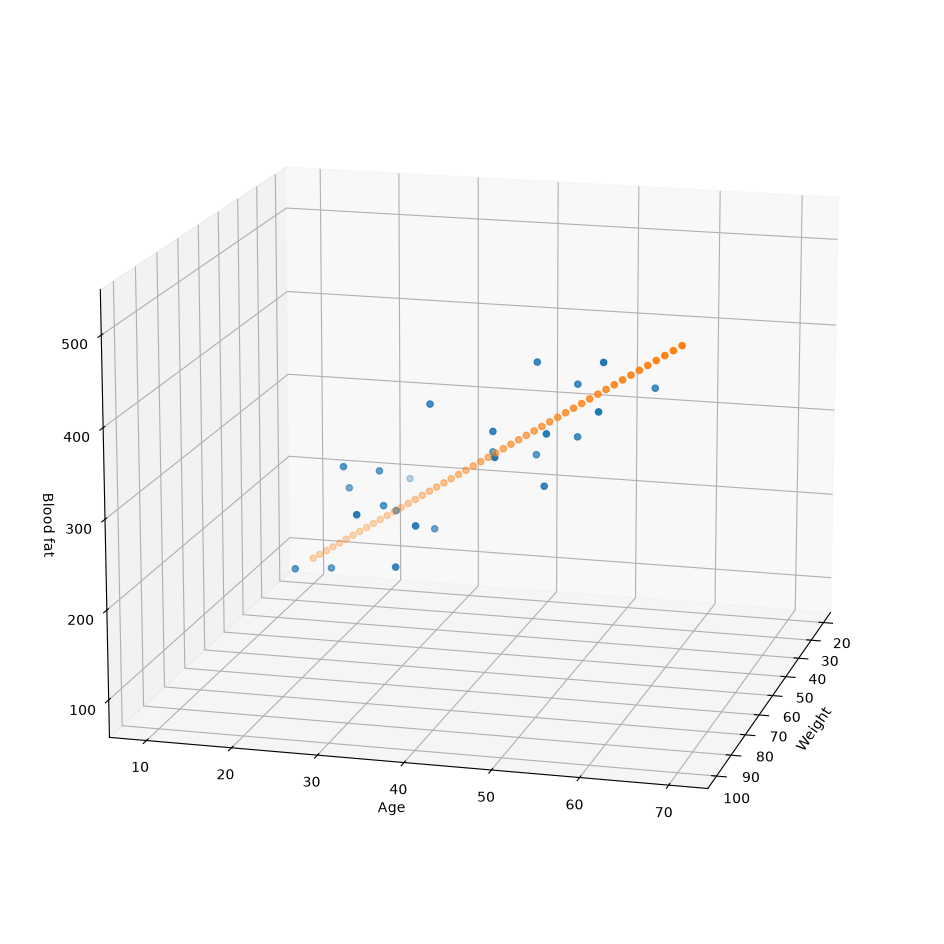

In [ ]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(xs, ys, zs) # 실제 데이터
ax.scatter(x, y, Z) # 임시 데이터
ax.set_xlabel('Weight')
ax.set_ylabel('Age')
ax.set_zlabel('Blood fat')
ax.view_init(15, 15)
plt.show()